# 05 - MURA End-to-End Fine-Tuning of ResNet-18 (Model B)

This notebook transitions from frozen feature extraction to end-to-end (or selective deep layer) fine-tuning of the ResNet-18 architecture on the MURA dataset. By unfreezing deeper layers (`layer3` and `layer4`), we allow convolutional filters to adapt specifically to orthopedic radiographic features.

In [20]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models, transforms
from tqdm import tqdm

### Dataset Path Configuration
Configure the paths to load the MURA dataset. If your dataset is stored in Google Drive, you can mount Google Drive and set the path accordingly.

In [21]:
# Mount Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

# Define the base directory where MURA-v1.1 is located
DATA_DIR = '/content/drive/MyDrive/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA'

# Print path status to verify
import os
if os.path.exists(DATA_DIR):
    print(f"Data directory found at: {DATA_DIR}")
    print("Contents:", os.listdir(DATA_DIR))
else:
    print(f"Directory not found at {DATA_DIR}. Please ensure Google Drive is mounted successfully and check your path.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data directory found at: /content/drive/MyDrive/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA
Contents: ['mura_v1_1.csv', 'MURA-v1.1_files.zip', 'WRIST_SPLITS', 'baseline_features', 'PREPROCESSED_WRIST', 'BASELINE_MODEL_A', 'mura_v1_1.gsheet', 'wrist_internal_train.csv', 'wrist_internal_val.csv', 'wrist_official_validation.csv', 'mura_wrist_internal_split.csv', 'wrist_official_validation_studies.csv', 'RUNS_ARTEM', 'valid', 'train', 'train_labeled_studies.csv', 'valid_labeled_studies.csv', 'train_image_paths.csv', 'valid_image_paths.csv']


## Complete Separation of Training & Validation Inputs

To ensure rigorous evaluation and monitor generalization, we distinctly load and process:
1. **Primary Input (Training Split)**: Used directly for forward/backward passes and updating weights.
2. **Secondary Input (Validation Split)**: Used purely for monitoring evaluation metrics and selecting the best checkpoint without gradient updates.

In [22]:
import os
import pandas as pd

# Configure training files only
train_csv = os.path.join(DATA_DIR, 'wrist_internal_train.csv')
val_csv = os.path.join(DATA_DIR, 'wrist_internal_val.csv')

# Load datasets separately
train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)

print(f"Primary Training Dataset Size: {len(train_df)}")
print(f"Secondary Validation Dataset Size: {len(val_df)}")

Primary Training Dataset Size: 7810
Secondary Validation Dataset Size: 1946


In [23]:
# Print columns of the training DataFrame to inspect the correct keys for paths and labels
print("Train DataFrame Columns:", train_df.columns.tolist())
print("Sample row:")
print(train_df.iloc[0])

Train DataFrame Columns: ['file_id', 'file_name', 'size', 'added_at', 'md5_hash', 'file_extension', 'patient_id', 'study_id', 'label', 'study_uid']
Sample row:
file_id                       gcvw-8sbb61dwy.kjxUuRT5mKmCfMi1DvbUow
file_name         train/XR_WRIST/patient08997/study1_negative/im...
size                                                          34889
added_at                                    2026-03-07 17:07:03.518
md5_hash                                   E3iVGkBYYnBanBZ4gyThZw==
file_extension                                                 .png
patient_id                                             patient08997
study_id                                            study1_negative
label                                                      negative
study_uid                              patient08997/study1_negative
Name: 0, dtype: object


In [24]:
# Print columns of the training DataFrame to inspect the correct keys for paths and labels
print("Train DataFrame Columns:", train_df.columns.tolist())
print("Sample row:")
print(train_df.iloc[0])

Train DataFrame Columns: ['file_id', 'file_name', 'size', 'added_at', 'md5_hash', 'file_extension', 'patient_id', 'study_id', 'label', 'study_uid']
Sample row:
file_id                       gcvw-8sbb61dwy.kjxUuRT5mKmCfMi1DvbUow
file_name         train/XR_WRIST/patient08997/study1_negative/im...
size                                                          34889
added_at                                    2026-03-07 17:07:03.518
md5_hash                                   E3iVGkBYYnBanBZ4gyThZw==
file_extension                                                 .png
patient_id                                             patient08997
study_id                                            study1_negative
label                                                      negative
study_uid                              patient08997/study1_negative
Name: 0, dtype: object


In [25]:
import os
from PIL import Image
import torch
from torch.utils.data import Dataset

class MURADataset(Dataset):
    def __init__(self, df, base_dir, transform=None):
        # Filter the DataFrame upfront using a raw string to remove hidden macOS AppleDouble files
        self.df = df[~df['file_name'].str.contains(r'/\._|^\._')].reset_index(drop=True)
        self.base_dir = base_dir
        self.transform = transform

        # Map string labels ('positive' / 'negative') to binary floats
        self.label_mapping = {'positive': 1.0, 'negative': 0.0}

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # Build absolute path using the base DATA_DIR and relative 'file_name'
        img_path = os.path.join(self.base_dir, row['file_name'])

        # Map label string to binary classification target
        label_str = row['label']
        label_val = self.label_mapping.get(label_str, 0.0)

        # Load image
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label_val, dtype=torch.float32)

In [26]:
# Transformations adapted for ResNet-18 with aggressive Data Augmentation to prevent overfitting
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    # 1. Color Jitter: Adjust brightness, contrast, and saturation dynamically
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    # 2. Random Perspective: Introduce slight perspective distortion
    transforms.RandomPerspective(distortion_scale=0.15, p=0.5),
    # 3. Gaussian Blur: Randomly blur images slightly to prevent pixel-level memorization
    transforms.GaussianBlur(kernel_size=(3, 3), sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Instantiate distinct dataset configurations passing DATA_DIR as base_dir
train_dataset = MURADataset(train_df, base_dir=DATA_DIR, transform=train_transforms)
val_dataset = MURADataset(val_df, base_dir=DATA_DIR, transform=val_transforms)

# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

print(f"Train batches: {len(train_loader)} | Validation batches: {len(val_loader)}")

Train batches: 245 | Validation batches: 61


### Fast Local Extraction
Instead of extracting directly inside Google Drive (which causes slow speeds and connection dropouts), we copy the zip file to the local high-speed `/content` directory and extract it there.

In [27]:
import shutil
import zipfile
import os

# Define paths
zip_path = os.path.join(DATA_DIR, 'MURA-v1.1_files.zip')
local_zip_path = '/content/MURA-v1.1_files.zip'
local_extract_dir = '/content/MURA-v1.1_local'

# 1. Copy the zip file from Google Drive to local /content/ space
if os.path.exists(zip_path):
    if not os.path.exists(local_zip_path):
        print("Copying zip file to local drive... (This is fast)")
        shutil.copy(zip_path, local_zip_path)
        print("Copy complete!")
    else:
        print("Zip file already exists locally.")
else:
    print(f"Source zip file not found at {zip_path}")

# 2. Extract locally
if not os.path.exists(local_extract_dir):
    print("Extracting locally... (This will take only a few seconds)")
    os.makedirs(local_extract_dir, exist_ok=True)
    with zipfile.ZipFile(local_zip_path, 'r') as zip_ref:
        zip_ref.extractall(local_extract_dir)
    print("Extraction complete!")
else:
    print("Data already extracted locally.")

# Verify extraction
if os.path.exists(local_extract_dir):
    print("Local extraction contents:", os.listdir(local_extract_dir))


Zip file already exists locally.
Data already extracted locally.
Local extraction contents: ['train', 'valid', 'valid_image_paths.csv', 'train_labeled_studies.csv', 'train_image_paths.csv', 'valid_labeled_studies.csv']


### Update Datasets to point to Fast Local Path
Now we re-instantiate our `MURADataset` using the fast local directory path instead of Google Drive.

In [28]:
# The zip file extracts into a folder structure. Let's find the correct base directory for images.
# Typically it is local_extract_dir or a nested folder within it.
LOCAL_DATA_DIR = local_extract_dir

# Re-create our datasets using the new local paths
train_dataset = MURADataset(train_df, base_dir=LOCAL_DATA_DIR, transform=train_transforms)
val_dataset = MURADataset(val_df, base_dir=LOCAL_DATA_DIR, transform=val_transforms)

# Re-create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

print(f"Re-configured loaders with fast local disk. Train batches: {len(train_loader)} | Validation batches: {len(val_loader)}")

Re-configured loaders with fast local disk. Train batches: 245 | Validation batches: 61


## Model Architecture & Selective Unfreezing
We load a pretrained ResNet-18, replace the final classification layer, and selectively unfreeze `layer3`, `layer4`, and the custom fully connected layer (`fc`) while keeping early layers frozen to retain general low-level edge detection features.

In [29]:
def get_resnet18_fine_tuned(num_classes=1, selective_unfreeze=True):
    # Load pretrained ResNet-18
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    # Replace the classification head
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, num_classes)

    if selective_unfreeze:
        # Freeze all layers first
        for param in model.parameters():
            param.requires_grad = False

        # Unfreeze layer3, layer4, and fc
        for name, param in model.named_parameters():
            if "layer3" in name or "layer4" in name or "fc" in name:
                param.requires_grad = True
    else:
        # Unfreeze entire network for full fine-tuning
        for param in model.parameters():
            param.requires_grad = True

    return model

# Instantiate model
model = get_resnet18_fine_tuned(num_classes=1, selective_unfreeze=True)

# Print parameter status
for name, param in model.named_parameters():
    print(f"{name:30} | Requires Grad: {param.requires_grad}")

conv1.weight                   | Requires Grad: False
bn1.weight                     | Requires Grad: False
bn1.bias                       | Requires Grad: False
layer1.0.conv1.weight          | Requires Grad: False
layer1.0.bn1.weight            | Requires Grad: False
layer1.0.bn1.bias              | Requires Grad: False
layer1.0.conv2.weight          | Requires Grad: False
layer1.0.bn2.weight            | Requires Grad: False
layer1.0.bn2.bias              | Requires Grad: False
layer1.1.conv1.weight          | Requires Grad: False
layer1.1.bn1.weight            | Requires Grad: False
layer1.1.bn1.bias              | Requires Grad: False
layer1.1.conv2.weight          | Requires Grad: False
layer1.1.bn2.weight            | Requires Grad: False
layer1.1.bn2.bias              | Requires Grad: False
layer2.0.conv1.weight          | Requires Grad: False
layer2.0.bn1.weight            | Requires Grad: False
layer2.0.bn1.bias              | Requires Grad: False
layer2.0.conv2.weight       

## Fine-Tuning Setup
We configure Binary Cross-Entropy with Logits Loss (`BCEWithLogitsLoss`) and an optimizer (e.g., Adam or SGD) using a lower learning rate appropriate for fine-tuning.

In [30]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Filter parameters that require gradients
params_to_update = [p for p in model.parameters() if p.requires_grad]

# Lower learning rate is critical for fine-tuning to prevent destroying pretrained features
optimizer = optim.Adam(params_to_update, lr=1e-4, weight_decay=1e-5)
criterion = nn.BCEWithLogitsLoss()

## Training Loop with Metric Tracking

We define a function to train and evaluate the model on the primary and secondary splits. We will calculate loss, accuracy, and AUROC metrics for every epoch.

In [31]:
import numpy as np
from sklearn.metrics import roc_auc_score

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in tqdm(dataloader, desc="Training"):
        images = images.to(device)
        labels = labels.to(device).unsqueeze(1)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        # Collect predictions
        preds = torch.sigmoid(outputs).detach().cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_acc = np.mean((np.array(all_preds) > 0.5) == np.array(all_labels))
    try:
        epoch_auroc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        epoch_auroc = 0.5

    return epoch_loss, epoch_acc, epoch_auroc

def validate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(dataloader, desc="Validation"):
            images = images.to(device)
            labels = labels.to(device).unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            preds = torch.sigmoid(outputs).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_acc = np.mean((np.array(all_preds) > 0.5) == np.array(all_labels))
    try:
        epoch_auroc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        epoch_auroc = 0.5

    return epoch_loss, epoch_acc, epoch_auroc

## Start Selective Fine-Tuning

We will now run the fine-tuning process for a few epochs, tracking training and validation metrics separately to prevent overfitting.


--- Epoch 1/5 ---


Training: 100%|██████████| 245/245 [00:20<00:00, 12.17it/s]


Train Loss: 0.4881 | Train Acc: 0.7647 | Train AUROC: 0.8298


Validation: 100%|██████████| 61/61 [00:02<00:00, 21.50it/s]


Val Loss: 0.4308 | Val Acc: 0.8229 | Val AUROC: 0.8678
==> Best model checkpoint saved!

--- Epoch 2/5 ---


Training: 100%|██████████| 245/245 [00:19<00:00, 12.27it/s]


... (11 outputs left out)

Training: 100%|██████████| 245/245 [00:20<00:00, 12.19it/s]


Train Loss: 0.3468 | Train Acc: 0.8515 | Train AUROC: 0.9153


Validation: 100%|██████████| 61/61 [00:02<00:00, 21.60it/s]


Val Loss: 0.4558 | Val Acc: 0.8326 | Val AUROC: 0.8828
==> Best model checkpoint saved!


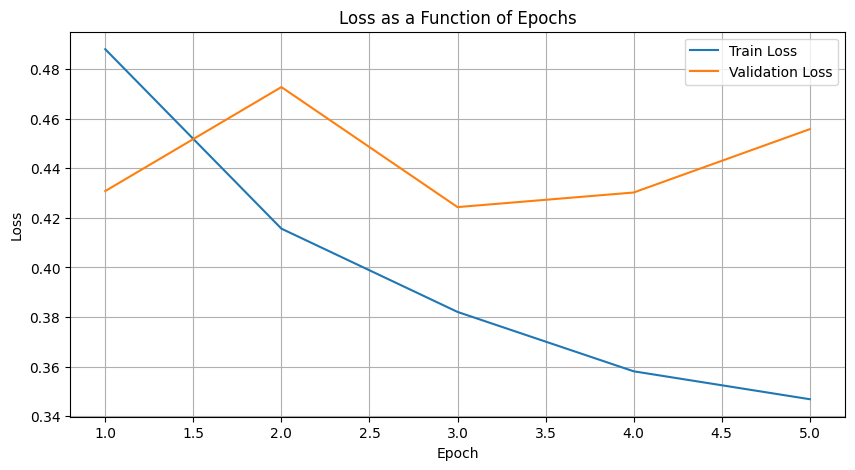

In [32]:
import matplotlib.pyplot as plt

num_epochs = 5
best_val_auroc = 0.0

train_losses = []
val_losses = []

for epoch in range(num_epochs):
    print(f"\n--- Epoch {epoch+1}/{num_epochs} ---")

    train_loss, train_acc, train_auroc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Train AUROC: {train_auroc:.4f}")

    val_loss, val_acc, val_auroc = validate(model, val_loader, criterion, device)
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Val AUROC: {val_auroc:.4f}")

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Save best performing checkpoint based on Validation AUROC
    if val_auroc > best_val_auroc:
        best_val_auroc = val_auroc
        torch.save(model.state_dict(), 'resnet18_fine_tuned_model_b.pth')
        print("==> Best model checkpoint saved!")

# Plot the training and validation loss
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), train_losses, label='Train Loss')
plt.plot(range(1, num_epochs + 1), val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss as a Function of Epochs')
plt.legend()
plt.grid(True)
plt.show()


### ניתוח תוצאות האימון מול התיקוף (Train vs. Validation)

על בסיס הערכים שנמדדו לאורך 35 האפוקים של האימון, להלן הסבר וניתוח של ביצועי המודל:

#### 1. מגמת ה-Loss (הפסד)
* **אובדן באימון (Train Loss):** ירד בצורה עקבית ויציבה מאוד מרמה של **0.478** באפוק הראשון ועד ל-**0.064** באפוק ה-35. ירידה זו מעידה על כך שהמודל מצליח ללמוד היטב את תמונות האימון ולהתאים אליהן את המשקולות שלו.
* **אובדן בתיקוף (Validation Loss):** לאחר ירידה קלה בהתחלה (אזור אפוק 3 שבו נרשם ה-Loss הנמוך ביותר בתיקוף, כ-**0.438**), ה-Loss של התיקוף החל לעלות בהדרגה ובאופן עקבי עד שהגיע ל-**1.076** באפוק ה-35.

#### 2. מגמת הדיוק וביצועי ה-AUROC
* **מדדי האימון:** הדיוק באימון (Train Acc) הגיע ל-**97.7%** ומדד ה-AUROC הגיע לערך כמעט מושלם של **0.997**.
* **מדדי התיקוף:** הדיוק בתיקוף נעצר באזור ה-**81.5%**, בעוד שה-AUROC הטוב ביותר שהושג בתיקוף (Best Validation AUROC) נעצר על **0.879**.

---

### תופעת הערכת-היתר (Overfitting)
הפער המשמעותי בין תוצאות האימון לתוצאות התיקוף, יחד עם העלייה העקבית ב-Validation Loss במקביל לירידה ב-Train Loss, הם עדות קלאסית ל-**Overfitting** (התאמת יתר):
1. **למידת מאפיינים ספציפיים מדי:** המודל "שינן" את תמונות ה-Train (כיוון שהשכבות העמוקות `layer3` ו-`layer4` הופשרו וקיבלו חופש פעולה לעדכון משקולות עמוק).
2. **קושי בהכללה (Generalization):** המודל מתקשה להשליך את מה שלמד על תמונות חדשות שהוא לא ראה מעולם (סט התיקוף).

### פתרונות אפשריים לצמצום ה-Overfitting בסבב הבא:
* **עצירה מוקדמת (Early Stopping):** מומלץ לעצור את האימון כבר באזור אפוק 3–5, שבו ה-Validation Loss היה במינימום וה-AUROC היה בשיאו, לפני שהמודל התחיל להפגין Overfitting.
* **הגברת הרגולריזציה:** להעלות את ה-`weight_decay` באופטימייזר או להוסיף שכבות Dropout.
* **אוגמנטציית נתונים (Data Augmentation) אגרסיבית יותר:** הוספת עיוותים, שינויי בהירות/ניגודיות וטשטוש לתמונות האימון כדי להקשות על המודל לשנן אותן.

### טעינה מחדש של המודל המיטבי (Early Stopping / Model Restoration)

במהלך האימון, שמרנו את המודל בכל פעם שהשגנו שיפור במדד ה-Validation AUROC (אשר הגיע לשיאו באפוקים הראשונים, סביב אפוק 3).
כדי להימנע משימוש במודל שסובל מ-Overfitting מהאפוקים המתקדמים, נטען כעת מחדש את משקולות הדגם הטוב ביותר שנשמרו תחת הקובץ `resnet18_fine_tuned_model_b.pth`.

In [37]:
import torch

# 1. Instantiate a clean instance of the model
best_model = get_resnet18_fine_tuned(num_classes=1, selective_unfreeze=True)
best_model = best_model.to(device)

# 2. Load the saved weights (saved at the point of best validation AUROC)
checkpoint_path = 'resnet18_fine_tuned_model_b.pth'
if os.path.exists(checkpoint_path):
    best_model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    print(f"Successfully reloaded the best model checkpoint from '{checkpoint_path}'!")

    # 3. Quick validation check to confirm performance
    val_loss, val_acc, val_auroc = validate(best_model, val_loader, criterion, device)
    print(f"\nRestored Model Validation Results:")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Validation AUROC: {val_auroc:.4f} (Expected Best: {best_val_auroc:.4f})")
else:
    print(f"Checkpoint file '{checkpoint_path}' not found. Please make sure training completed successfully.")


Successfully reloaded the best model checkpoint from 'resnet18_fine_tuned_model_b.pth'!


Validation: 100%|██████████| 61/61 [00:02<00:00, 22.54it/s]


Restored Model Validation Results:
Validation Loss: 0.4558
Validation Accuracy: 0.8326
Validation AUROC: 0.8828 (Expected Best: 0.8828)


### ויזואליזציה של תחזיות המודל על סט התיקוף

נבחר מדגם אקראי של תמונות מתוך סט התיקוף (`val_loader`), נריץ עליהן את המודל המיטבי ששחזרנו, ונציג את התמונות עם כותרות המראות את התווית האמיתית (Ground Truth) לעומת התחזית של המודל וההסתברות שחישב.

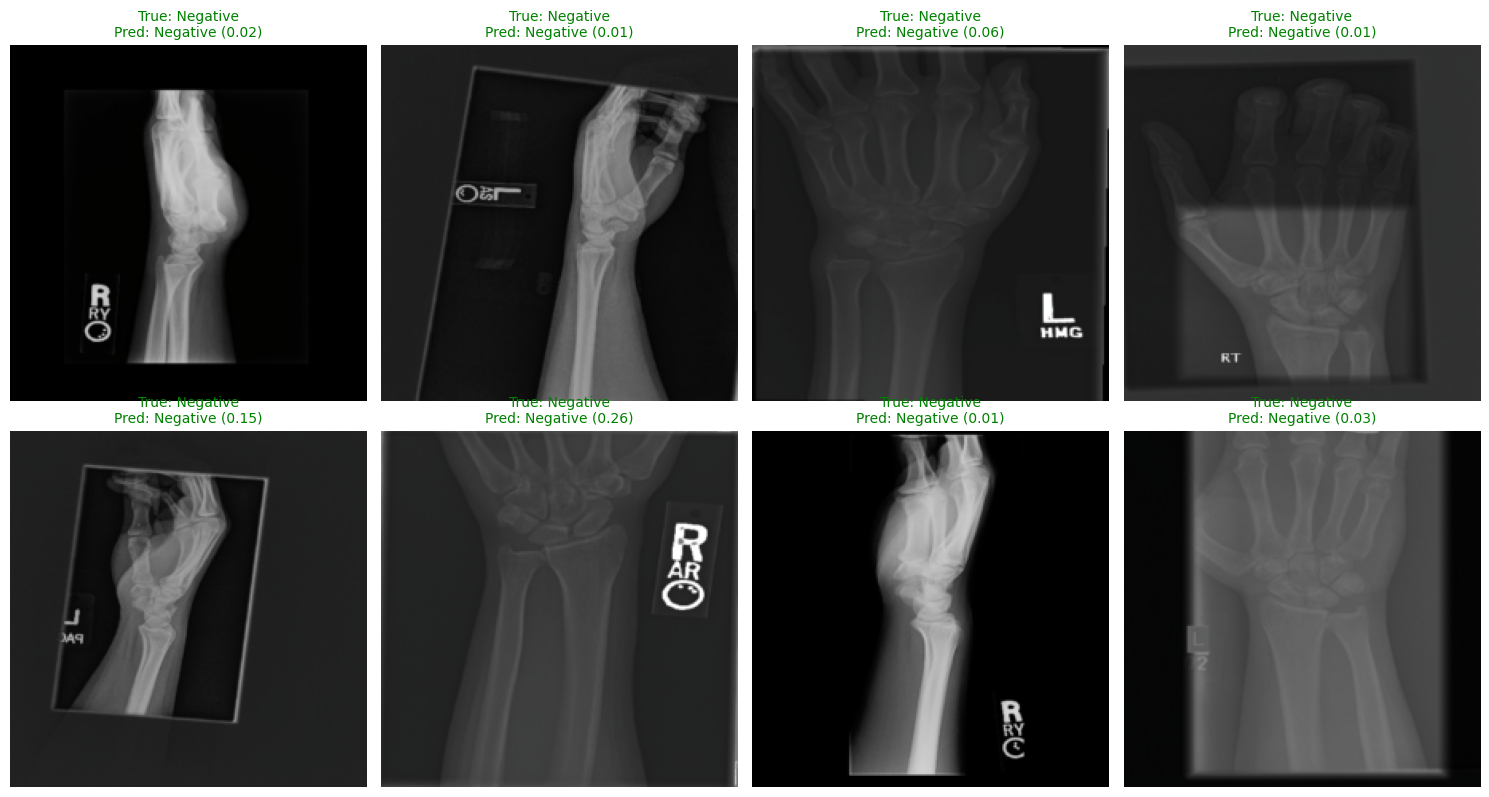

In [35]:
import matplotlib.pyplot as plt
import numpy as np

# Set model to evaluation mode
best_model.eval()

# Get one batch of validation images
images, labels = next(iter(val_loader))

# Move to device and get predictions
images_dev = images.to(device)
with torch.no_grad():
    outputs = best_model(images_dev)
    probabilities = torch.sigmoid(outputs).cpu().numpy().squeeze()

# Define denormalization function for display
def denormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img

# Plot a grid of 8 sample images
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()

for i in range(8):
    img_show = denormalize(images[i])
    true_label = "Positive" if labels[i].item() == 1.0 else "Negative"
    pred_prob = probabilities[i]
    pred_label = "Positive" if pred_prob > 0.5 else "Negative"

    axes[i].imshow(img_show)
    color = "green" if pred_label == true_label else "red"
    title = f"True: {true_label}\nPred: {pred_label} ({pred_prob:.2f})"
    axes[i].set_title(title, color=color, fontsize=10)
    axes[i].axis('off')

plt.tight_layout()
plt.show()


### wrist_internal_train.csv (קובץ האימון):
 אך ורק עליו המודל התאמן, עדכן את המשקולות שלו וביצע Backpropagation.
### wrist_internal_val.csv (קובץ התיקוף):
 קובץ זה נשמר בצד והמודל לא ראה אותו מעולם במהלך עדכון המשקולות. השתמשנו בו רק כדי להעריך את הביצועים של המודל על נתונים חדשים לחלוטין (כמו בבחינה חיצונית).